# Etapa 07: Abrir la prueba una sola vez

Las etapas 04, 05 y 06 dejaron modelos congelados (variables, hiperparámetros, calibración y umbral) sin mirar
nunca el periodo de prueba. Aquí abrimos ese periodo una sola vez, con `leer_prueba`, que deja constancia de cada
lectura, y medimos lo que hacen los modelos con datos que nadie usó para decidir. Primero mostramos lo congelado,
después abrimos la prueba y al final comparamos las dos cosas sin reajustar ni reelegir nada.

← Anterior: [Etapa 06: Agrupamiento](06_agrupamiento.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)

## Código del proyecto

La celda siguiente vuelve a crear el paquete `proyecto/` dentro de la sesión. Así el notebook funciona en Google Colab sin clonar ningún repositorio: Basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo y la sección se puede plegar desde su título. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (50 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 6 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (67 archivos, 205 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="1f10c52134e76465e5f1b56b9dccf9477750c87c9506372fb39ed9a9a43ecf2e",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import evaluacion_final as final

iniciar_etapa("07_evaluacion_final")
c = final.iniciar()
mostrar(c.encabezado)

## 1. Lo que quedó congelado

Desde aquí no cambiamos nada: Ni el modelo, ni las variables, ni los hiperparámetros, ni la calibración, ni el
umbral.

In [2]:
final.congelado(c).mostrar()

Análisis,Tipo,Modelo,Variables,Hiperparámetros,Calibración y umbral,Validación
carga_diaria,Regresión,Regresión lineal,grupo ampliado (16),ninguno (mínimos cuadrados),No aplica,"RMSE 14.59, habilidad 0.249"
no_conforme_recepcion,Clasificación,Regresión logística,grupo ampliado (51),C = 10.0,"Sigmoide, umbral 0.167","ROC-AUC 0.721, costo 2376, precisión 0.275"


## 2. Apertura de la prueba

Leemos tres bloques: La carga diaria (regresión), las muestras en recepción (clasificación y Bayes) y los no
conformes reensayados (VPP y regla de reensayo). Esta es la única celda del proyecto que toca la prueba y cada
lectura queda escrita en `artefactos/_etapas/lecturas_prueba.log`:

In [3]:
from proyecto.base.artefactos import leer_prueba

c.prueba_reg = leer_prueba(c.nombre_reg)                 # carga diaria de la prueba
c.prueba_clf = leer_prueba(c.nombre_clf)                 # muestras recibidas en la prueba
c.prueba_reensayo = leer_prueba(final.NOMBRE_REENSAYO)   # no conformes reensayados en la prueba
final.abrir_prueba(c).mostrar()

Los modelos congelados se usan tal cual salieron de las etapas 04 y 05. El de la carga recibe las variables de la
víspera y el clasificador da la probabilidad de no conformidad, que se compara con el umbral congelado. Así se ven
los primeros días y las primeras muestras de la prueba:

In [4]:
from proyecto.reporte.html import tabla_html

dias = c.prueba_reg.head(5)                                                 # primeros días de la prueba
carga = c.modelo_reg.predict(dias[c.reg["variables_entrada"]])              # modelo congelado en la etapa 04
muestras = c.prueba_clf.head(5)                                             # primeras muestras de la prueba
riesgo = c.modelo_clf.predict_proba(muestras[c.clf["variables_entrada"]])[:, 1]   # congelado en la etapa 05
tabla_dias = dias[[c.papeles_reg["fecha"], c.papeles_reg["objetivo"]]].assign(predicción=carga)
tabla_muestras = muestras[["id_muestra", "ensayo"]].assign(riesgo=riesgo, alerta=riesgo >= c.umbral)
mostrar(tabla_html(tabla_dias, "Carga predicha", decimales=1), tabla_html(tabla_muestras, "Riesgo y alerta", decimales=3))

fecha,muestras_dia,predicción
2026-01-02,22,36.9
2026-01-05,32,47.3
2026-01-06,31,48.7
2026-01-07,15,33.1
2026-01-08,39,35.3


id_muestra,ensayo,riesgo,alerta
M029900,Salmonella spp.,0.082,no
M029901,coliformes y E. coli,0.038,no
M029902,mesófilos aerobios,0.073,no
M029903,mohos y levaduras,0.050,no
M029904,mesófilos aerobios,0.074,no


## 3. Regresión: ¿Cuántas muestras van a llegar mañana?

El modelo congelado predice cada día con la información de la víspera y lo comparamos con las mismas referencias
ingenuas de la etapa 04. La habilidad se mide frente a la misma referencia de entonces.

In [5]:
final.regresion(c).mostrar()

Predictor,MAE,RMSE,R2,Habilidad
Regresión lineal,9.80,12.47,0.529,0.334
base_dia_anterior,20.47,26.04,-1.053,-0.390
base_media_5,14.65,18.73,-0.062,0.000


Métrica,Validación,Prueba,Prueba inf.,Prueba sup.
RMSE,14.591,12.466,11.201,13.658
MAE,11.030,9.802,8.716,10.856
R²,0.367,0.529,0.402,0.622
Habilidad,0.249,0.334,0.247,0.408


### 3.1 Residuos, fin de año y operación

La tolerancia práctica es la misma de la etapa 04 (en muestras por día) para que la prueba no mueva la vara con que
la juzgamos.

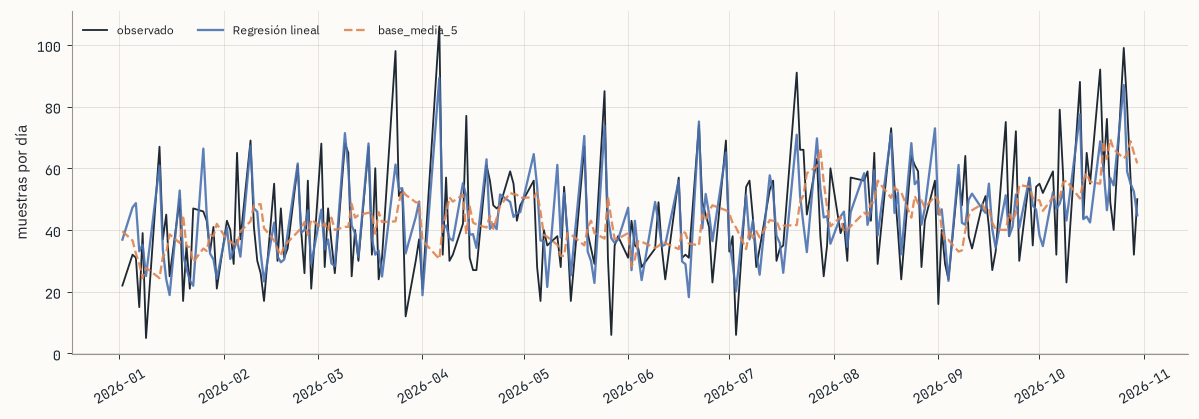

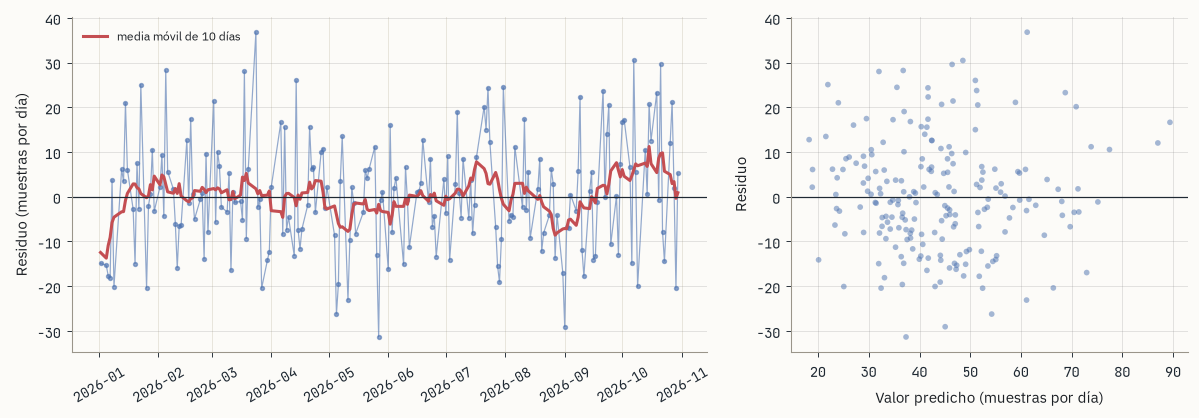

In [6]:
final.regresion_diagnostico(c).mostrar()

## 4. Clasificación: ¿Qué muestras están en riesgo?

Cada muestra de prueba recibe una probabilidad y la alerta se levanta con el umbral de validación. Al lado del costo
van la precisión y las alertas por semana porque un costo bajo con demasiadas falsas alarmas no le sirve a la
recepción.

Métrica,Validación,Prueba,Prueba inf.,Prueba sup.
ROC-AUC,0.721,0.724,0.705,0.743
Precisión media,0.245,0.243,0.216,0.276
Brier,0.075,0.075,0.072,0.080
Precisión,0.275,0.270,0.242,0.299
Recall,0.397,0.325,0.293,0.357
F1,0.325,0.295,0.267,0.324
Costo por muestra,0.363,0.381,0.358,0.409


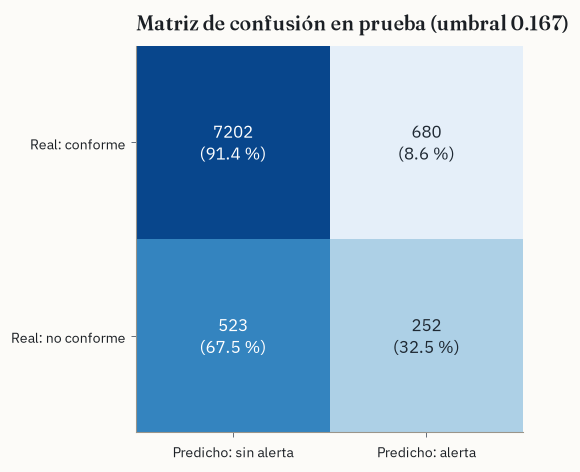

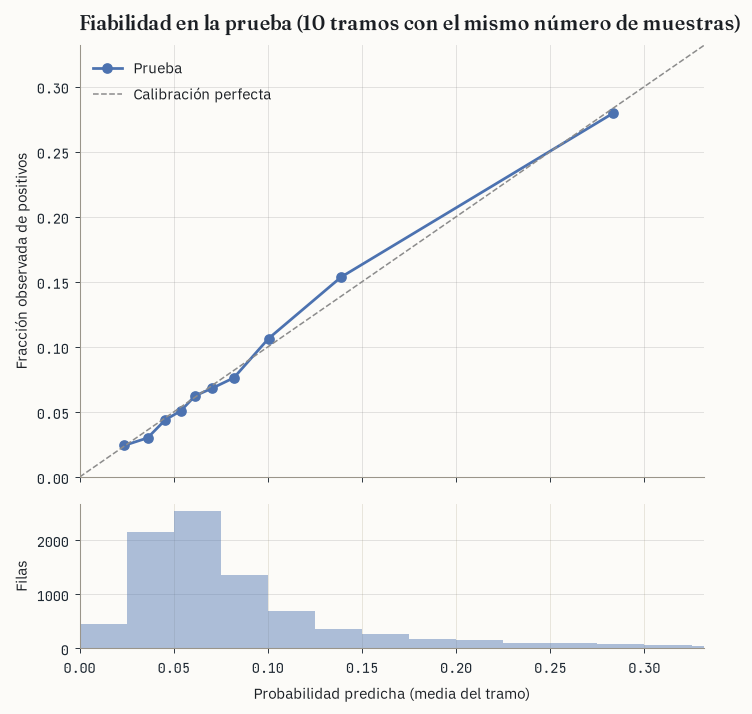

In [7]:
final.clasificacion(c).mostrar()

### 4.1 Retrospectiva: El umbral que habría convenido

Esto va solo por transparencia. Un umbral elegido en la prueba estaría ajustado a ella y su costo sería optimista,
así que esta celda no decide nada.

In [8]:
final.retrospectiva(c).mostrar()

## 5. Bayes en la prueba: ¿Qué tan probable es que un positivo sea falso?

Con la sensibilidad y la especificidad del desarrollo y la probabilidad del clasificador como previa de cada
muestra calculamos el VPP(x) de cada positivo. La referencia que se puede observar es el reensayo.

In [9]:
final.bayes_prueba(c).mostrar()

Ensayo,Positivos,VPP del ensayo (desarrollo),VPP(x) medio,Reensayados,Reensayo conforme esperado,Reensayo conforme observado
Pseudomonas aeruginosa,53,0.802,0.729,50,0.321,0.260
Salmonella spp.,3,0.897,0.917,2,0.141,0.000
Staphylococcus aureus,35,0.734,0.827,32,0.218,0.344
coliformes y E. coli,148,0.789,0.828,131,0.217,0.252
esterilidad,22,0.627,0.740,19,0.301,0.421
mesófilos aerobios,319,0.789,0.807,285,0.220,0.140
mohos y levaduras,195,0.787,0.763,172,0.269,0.326


### 5.1 Auditoría de la simulación

Solo existe porque el generador guardó la verdad oculta. Con datos reales no aplica.

In [10]:
final.auditoria(c).mostrar()

Ensayo,Positivos,VPP del ensayo (desarrollo),VPP(x) medio,Fracción realmente contaminada
Pseudomonas aeruginosa,53,0.802,0.729,0.792
Salmonella spp.,3,0.897,0.917,1.000
Staphylococcus aureus,35,0.734,0.827,0.714
coliformes y E. coli,148,0.789,0.828,0.797
esterilidad,22,0.627,0.740,0.591
mesófilos aerobios,319,0.789,0.807,0.875
mohos y levaduras,195,0.787,0.763,0.718


### 5.2 La regla de reensayo en la prueba

Aplicamos a los reensayos de la prueba el mismo borde que fijamos en la etapa 05, leído de su artefacto.

In [11]:
final.regla_reensayo(c).mostrar()

Periodo,Conformes con razón ≤ 0.22,Conformes con razón > 0.22,Fracción de conformes capturada
Desarrollo,0.777,0.152,0.510
Prueba,0.774,0.120,0.545


## 6. Agrupamiento

El agrupamiento no se evalúa en la prueba porque no hay una respuesta correcta con que compararlo. Resumimos lo
que dejó la etapa 06.

In [12]:
final.agrupamiento(c).mostrar()

## 7. Qué respondimos, qué tan bien y qué haríamos con los datos reales

Cerramos con las cuatro preguntas del laboratorio. Para cada una va la respuesta, la cifra de la prueba que la
respalda y lo que la limita. Después va lo que recomendaríamos, lo que no alcanzamos a resolver y los pasos para
correr todo con la exportación real. Las cifras son de la prueba salvo donde se dice otra cosa.

In [13]:
final.resumen(c).mostrar()

Pregunta del laboratorio,Respuesta,Evidencia,Limitación
¿Cuántas muestras llegarán mañana?,Regresión lineal con un error típico de 9.8 muestras sobre una media de 44.1,"RMSE 12.47 en prueba (14.59 en validación), habilidad 0.334",El 38 % de los días queda fuera de la tolerancia
¿Qué muestras están en riesgo?,"Alerta en recepción con umbral 0.167, unas 21 por semana","AUC 0.724, costo 3295 frente a 3875 sin modelo",Solo acierta el 27 % de las alertas
¿Qué tan probable es un falso positivo?,Uno de cada 5 positivos según controles y clasificador. Reensayar si el recuento es menor que 1.66 veces el límite,reensayo conforme 23.3 % observado frente a 24.1 % esperado,El reensayo no es la verdad: También falla
¿Qué grupos existen?,4 perfiles de muestra y 3 segmentos de clientes,"silueta 0.148, Hopkins 0.714","Fronteras difusas, uso descriptivo"


In [14]:
final.terminar(c)

← Anterior: [Etapa 06: Agrupamiento](06_agrupamiento.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)